# Lab 4 — Hydroloop soil-moisture balance

**Objective:** run the pixel monthly water balance to produce surface runoff, percolation and the **green/blue ET split** the WA+ sheets need — the step where satellite hydrology becomes water accounting.

**Depends on Labs 1–3:** `gridspec.json`, `basin_mask.nc`, `P_corrected.nc`, `ET.nc`, `LAI.nc`, `lu.nc`, `basin_config.json` (pulled from Drive in section 2).

This lab is pure Python and runs offline; Earth Engine (⚠️) is only needed for the optional NRD, soil-AWC (§4c) and satellite-check (§9) cells.

### 🧭 What we are really doing here

Satellites told us how much water *left* as ET, but not *where it came from*. This lab is the little model that fills that gap. Picture one bucket of soil under every pixel: rain falls in, some is caught by leaves (interception), some runs off, some soaks down (percolation), and what the soil and plants evaporate is the ET. Stepping that bucket month by month lets us split ET into **green** (paid for by rain) and **blue** (paid for by irrigation or a shallow water table) — and that split is the very heart of water accounting.

It also hands us runoff and percolation, which matter especially in Nepal because most tributaries are **ungauged** — so the model's runoff *is* our outflow estimate. Keep the honesty rule in view: this is a partitioning tool, not a calibrated rainfall-runoff model. Its job is a physically consistent, mass-conserving split — not a gauge-perfect hydrograph — and that is exactly what the sheets need.

## 0 · Environment setup  *(Colab or local — auto-detected)*

**What this does.** Mounts Drive, points at the **`west_rapti`** folder, installs packages, imports the
engine as `kw`. Same across all labs.

In [1]:
import os, sys, shutil
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    KW_DIR = '/content/drive/MyDrive/west_rapti'
    get_ipython().system('pip -q install earthengine-api geemap geedim rioxarray wapordl')
else:
    KW_DIR = '.'
OUT_DIR = os.path.join(KW_DIR, 'outputs') if IN_COLAB else 'outputs'

# --- always load the engine from KW_DIR (Drive), never a stale copy elsewhere ---
_kw = os.path.abspath(KW_DIR)
if os.path.abspath('.') != _kw:
    for _f in ('west_rapti.py', 'westrapti_prep.py'):
        if os.path.exists(_f): os.remove(_f)
for _p in (KW_DIR, _kw):
    while _p in sys.path: sys.path.remove(_p)
sys.path.insert(0, _kw)
for _m in ('west_rapti', 'westrapti_prep'): sys.modules.pop(_m, None)
# --- participant settings (written once by 00_Setup.ipynb) ---
import json as _json
_pj = os.path.join(KW_DIR, 'participant.json')
PARTICIPANT = _json.load(open(_pj)) if os.path.exists(_pj) else {}
EE_PROJECT = PARTICIPANT.get('ee_project', '')
if not EE_PROJECT:
    print('⚠️  No Earth Engine project set — run 00_Setup.ipynb first (or set EE_PROJECT in CONFIG).')
print('Running on', 'Colab' if IN_COLAB else 'local', '| outputs ->', OUT_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 100.7 MB/s eta 0:00:00
Running on Colab | outputs -> /content/drive/MyDrive/west_rapti/outputs


## 1 · Imports & **configuration**

**What this does.** Loads the stack and sets the CONFIG. The knobs that matter most:

| knob | meaning |
|---|---|
| `CF` | SCS-CN factor: splits infiltration vs runoff — changes **timing**, not the annual volume (see §5b) |
| `INT_K` | canopy interception capacity per unit LAI per rain day (mm) |
| `NET_BLUE` | subtract blue ET from the outflow (it is drawn from the basin's rivers and groundwater) |
| `AWC` / `AWC_SOURCE` | soil available water content: a constant, or a **spatial** field from soil data (`soilgrids` = FC−PWP, recommended) |
| `SM_INIT` | initial soil moisture as a fraction of the bucket size |
| `INT_SOURCE` | interception from `lai` or WaPOR `wapor` |
| `SNOW_ON` / `GLACIER_ON` | temperature-index snow / glacier melt (glaciers off for the West Rapti) |
| `MODEL_SOURCE` | `hydroloop` (default) or ingest external `mike_she` outputs |

**Note.** Root depth per WA+ class lives in `kw.ROOT_DEPTH_M`; the soil bucket is
`SMmax = root_depth(m) × 1000 × AWC(m³/m³)`.

In [2]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr, json
import importlib, west_rapti as kw; importlib.reload(kw)

# ---------------- CONFIG (edit these) ----------------
NRD_SOURCE = 'estimate'    # 'estimate' (from monthly P) | 'gee' (CHIRPS daily count, ⚠️)
EE_PROJECT = EE_PROJECT or 'your-ee-project-id'   # only for NRD_SOURCE=='gee'
CF   = 1.0                 # SCS-CN factor: infiltration vs runoff split (timing) — it cannot change the annual volume
AWC  = 0.12               # fallback uniform soil available water content (m3/m3)
AWC_SOURCE = 'soilgrids'    # 'constant' (use AWC above) | 'soilgrids' (ISRIC FC-PWP, recommended) | 'openlandmap' (FC only)
PWP_FRACTION = 0.40       # only for AWC_SOURCE='openlandmap': assume wilting point = FRACTION x field capacity
SM_INIT = 0.5             # initial soil moisture as a fraction of SMmax
INT_K   = 0.2             # interception capacity per unit LAI per rain day (mm): 0.2–0.4, higher for dense forest
NET_BLUE = True           # subtract blue ET from outflow (blue water comes from the basin's rivers / groundwater)
INT_SOURCE = 'lai'          # interception: 'lai' (from LAI) | 'wapor' (WaPOR L1-I, matches WA_jordan)
START, END = '2021-01-01', '2025-01-01'   # only used when INT_SOURCE=='wapor' or NRD_SOURCE=='gee'
# --- snow (temperature-index / degree-day). Redistributes precip in time for snow-fed basins ---
SNOW_ON = True             # kept on: minor winter snow on the highest ridges; builds the T cube Lab 6 needs
DDF     = 4.0              # degree-day melt factor (mm/°C/day); ~3-5 seasonal snow, higher on ice
T_SNOW  = 1.0             # air temp (°C) around which precip switches snow<->rain
T_MELT  = 0.0            # melt threshold temperature (°C)
LAPSE   = -0.0065         # temperature lapse rate (°C per m) for the DEM-based T cube — test it with the §9 MODIS check
T0_SEALEVEL = [16,19,24,29,31,31,30,29,28,26,21,17]  # sea-level monthly mean °C (Jan..Dec) — western Terai/Dang; edit or load ERA5-Land
GLACIER_ON = False        # West Rapti tops out ~3.6 km — no glaciers (set True for glaciated basins such as the Koshi)
DDF_ICE    = 7.0          # bare-ice degree-day factor (mm/°C/day); higher than snow (darker ice)
GLACIER_SOURCE = 'rgi'    # glacier mask: 'rgi' (RGI v7 outlines via GEE ⚠️) | 'vector' (local file) | 'auto' (elev/class)
GLACIER_VECTOR = ''       # path to a downloaded RGI/GLIMS/ICIMOD shapefile or GeoJSON (for GLACIER_SOURCE='vector')
GLACIER_MIN_KM2 = 0.05    # drop glaciers smaller than this (RGI/vector have an area_km2 field)
SNOWLINE_M = 5000         # fallback only (GLACIER_SOURCE='auto'): pixels above this, or WA+ glacier class 1, are ice
MODEL_SOURCE = 'hydroloop'  # 'hydroloop' (default) | 'mike_she' (ingest MIKE SHE outputs — optional)
MIKE_CRS = 'EPSG:32645'     # CRS of the MIKE SHE model grid (only for 'mike_she')
MIKE_MAP = {                # cube_key -> {dfs2 path, item, agg}; uncomment & edit for your results
  # 'et':    {'path':'ET.dfs2',          'item':'ET',                 'agg':'sum'},
  # 'i':     {'path':'Interception.dfs2','item':'Canopy interception','agg':'sum'},
  # 'sro':   {'path':'OL.dfs2',          'item':'overland flow',      'agg':'sum'},
  # 'perc':  {'path':'Recharge.dfs2',    'item':'recharge',           'agg':'sum'},
  # 'etincr':{'path':'ET_irr.dfs2',      'item':'irrigation ET',      'agg':'sum'},
  # 'etrain':{'path':'ET_rain.dfs2',     'item':'rainfed ET',         'agg':'sum'},
}
# root depth per WA+ class is kw.ROOT_DEPTH_M (edit there for Nepal soils)
# -----------------------------------------------------

## 2 · Pull Labs 1–3 outputs from Drive

**What this does.** Loads the grid, mask, and the analysis-ready cubes from upstream — bias-corrected
precipitation, ET, LAI and the WA+ land-use grid — all on the common 300 m grid.

months 48 | grid (394, 556) | ET months 48
P     shape=(48, 394, 556) finite=10,135,388/10,515,072 min=0 mean=140 max=953
ET    shape=(48, 394, 556) finite=10,515,072/10,515,072 min=0 mean=62.2 max=396
LAI   shape=(48, 394, 556) finite=10,333,776/10,515,072 min=0 mean=1.8 max=7
lu    shape=(394, 556) finite=  219,064/219,064   min=1 mean=4.05 max=9
mask  shape=(394, 556) finite=   70,665/219,064   min=1 mean=1 max=1

P    dims=('y', 'x')    y[3055650.0,3173550.0] x[554550.0,721050.0]
mask dims=('y', 'x') y[3055650.0,3173550.0] x[554550.0,721050.0]
mask==P grid: True | coord ranges overlap: True
P basin-mean  min=0.0597  mean=145  max=618
ET basin-mean  min=19.2  mean=65  max=102
LAI basin-mean  min=1.25  mean=2.09  max=3.52


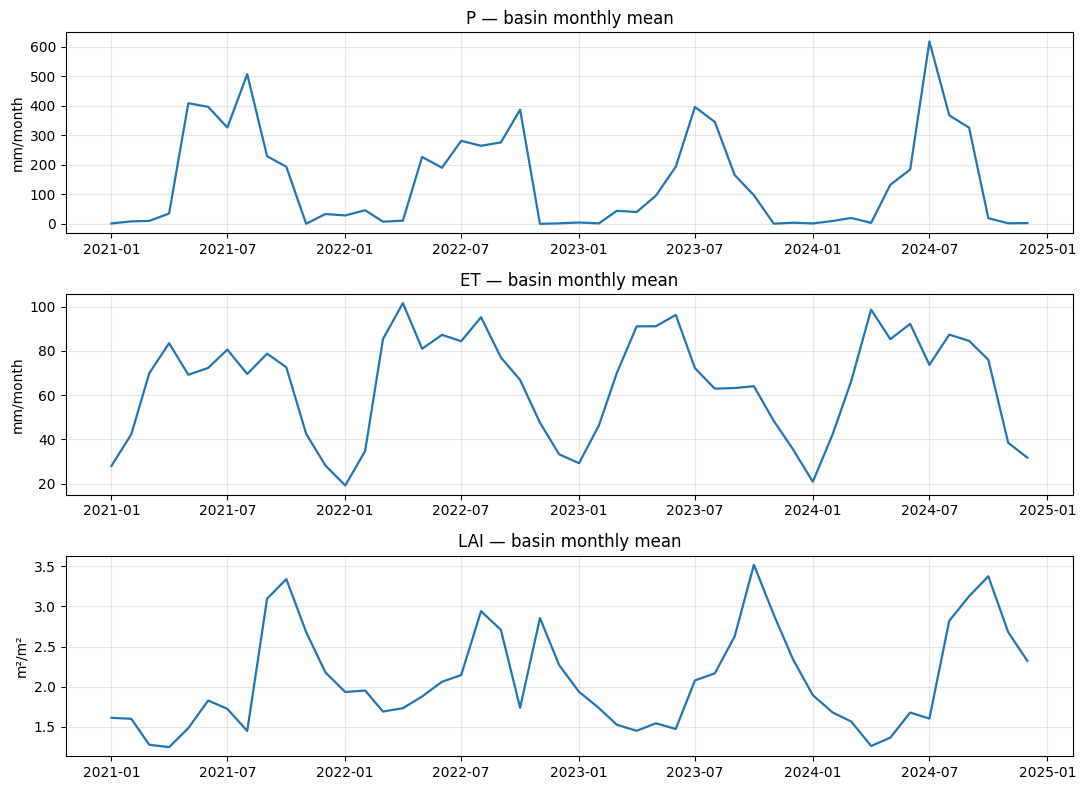

In [3]:
import numpy as np, matplotlib.pyplot as plt

kw.load_inputs(['gridspec.json', 'basin_mask.nc', 'P_corrected.nc', 'ET.nc', 'LAI.nc', 'lu.nc',
                'dem_utm.tif', 'basin_config.json'], OUT_DIR)
gs = json.load(open('gridspec.json')); UTM = gs['crs']

mask = xr.open_dataset('basin_mask.nc')['basin_mask']
P   = xr.open_dataset('P_corrected.nc')['P']
ET  = xr.open_dataset('ET.nc')['ET']
LAI = xr.open_dataset('LAI.nc')['LAI']
lu  = xr.open_dataset('lu.nc')['lu']

print('months', P.sizes['time'], '| grid', P.shape[-2:], '| ET months', ET.sizes['time'])

# --- (1) are the cubes actually populated? ---
def summ(name, da):
    a = np.asarray(da.values, float); fin = np.isfinite(a); n = int(fin.sum())
    if n:
        v = a[fin]
        print(f'{name:5s} shape={tuple(da.shape)} finite={n:>9,d}/{a.size:<9,d} '
              f'min={v.min():.3g} mean={v.mean():.3g} max={v.max():.3g}')
    else:
        print(f'{name:5s} shape={tuple(da.shape)} finite=0  --> ALL NaN / EMPTY')
for nm, da in [('P',P),('ET',ET),('LAI',LAI),('lu',lu),('mask',mask)]:
    summ(nm, da)

# --- (2) do mask and P share coordinate space? ---
def extent(da):
    y = da[da.dims[-2]].values; x = da[da.dims[-1]].values
    return float(y.min()), float(y.max()), float(x.min()), float(x.max())
pe, me = extent(P), extent(mask)
print(f'\nP    dims={P.dims[-2:]}    y[{pe[0]:.1f},{pe[1]:.1f}] x[{pe[2]:.1f},{pe[3]:.1f}]')
print(f'mask dims={mask.dims[-2:]} y[{me[0]:.1f},{me[1]:.1f}] x[{me[2]:.1f},{me[3]:.1f}]')
overlap = not (me[1] < pe[0] or me[0] > pe[1] or me[3] < pe[2] or me[2] > pe[3])
print('mask==P grid:', mask.shape == P.isel(time=0).shape, '| coord ranges overlap:', overlap)
if not overlap:
    print('  !! mask and P are in DIFFERENT coordinate spaces (CRS/units) — .where(mask==1) is\n'
          '     all-NaN no matter how you interp. Fix upstream: mask = kw.regrid("basin_mask.nc", gs) > 0.5')

# --- (3) basin monthly mean (zonal stat), mask aligned to each cube's grid ---
def basin_mean(da):
    m = mask
    if m.shape != da.isel(time=0).shape:
        r = {k:v for k,v in {m.dims[-2]:da.dims[-2], m.dims[-1]:da.dims[-1]}.items() if k!=v}
        if r: m = m.rename(r)
        m = m.interp({da.dims[-2]:da[da.dims[-2]], da.dims[-1]:da[da.dims[-1]]}, method='nearest')
    return da.where(m > 0.5).mean(dim=da.dims[-2:])

fig, ax = plt.subplots(3, 1, figsize=(11, 8))
for a, (nm, da, unit) in zip(ax, [('P',P,'mm/month'),('ET',ET,'mm/month'),('LAI',LAI,'m²/m²')]):
    s = basin_mean(da)
    a.plot(da.time.values, np.asarray(s.values), lw=1.6)
    a.set_title(f'{nm} — basin monthly mean'); a.set_ylabel(unit); a.grid(alpha=.3)
    print(f'{nm} basin-mean  min={float(s.min()):.3g}  mean={float(s.mean()):.3g}  max={float(s.max()):.3g}')
plt.tight_layout(); plt.show()

**In plain terms — snow first.** In a snow-fed basin the plain soil-bucket has a blind spot: it treats winter precipitation as if it were rain that runs off immediately. It does not. Snow banks up in the cold months and is released as **melt** in spring and summer — so the water arrives *later*, and warming shifts *when* it arrives. This step splits precipitation into snow vs rain by temperature, builds a snowpack, melts it with a degree-day rule, and hands the soil balance the **liquid input** (rain + melt) instead of raw precipitation. It is where a warming scenario actually changes the dry-season answer.

## 2b · Snow & glacier: split precipitation, route the melt  (temperature-index)  ⚠️

Air temperature is built from the DEM and a monthly sea-level cycle with a lapse rate (screening default — swap in **ERA5-Land** or DHM station temperature where you have it). Seasonal snow accumulates and melts; on **glacier** pixels, exposed ice melts once the seasonal snow is gone (net mass loss, a negative ΔS). The glacier mask uses **real outlines**: `GLACIER_SOURCE='rgi'` burns the Randolph Glacier Inventory v7 (`projects/sat-io/open-datasets/RGI/RGI_VECTOR_MERGED_V7`, via GEE, ⚠️); `'vector'` rasterises a downloaded RGI / GLIMS / **ICIMOD** shapefile or GeoJSON (`GLACIER_VECTOR`); `'auto'` is an offline elevation/class fallback. Set `SNOW_ON=False` to skip snow entirely.

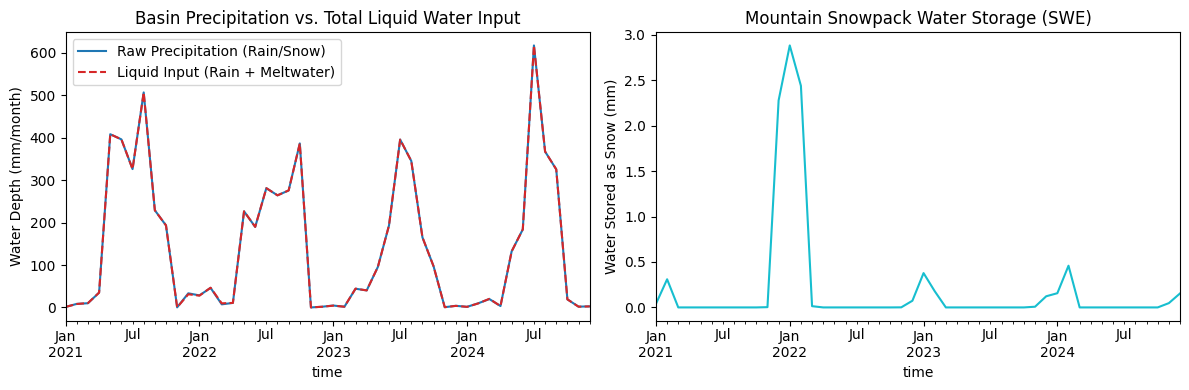

Snow Model Summary: ACTIVE | Total Annual Melt = 12.3 Million Cubic Meters | Bare-Ice Glacier Melt = 0.0 Million Cubic Meters


In [4]:
if SNOW_ON:
    # 1. Prepare the terrain elevation map to match our project grid (300m pixels)
    elev = kw.regrid('dem_utm.tif', gs).squeeze(drop=True)
    # regrid matches gs resolution but keeps the DEM's larger native EXTENT, so elev is bigger
    # than P's grid. snow_module runs in raw numpy (no coord alignment), so pin elev to P's grid
    # or T won't broadcast against P.
    _yd, _xd = P.dims[-2], P.dims[-1]
    def _to_P_grid(a, method='nearest'):
        ren = {k: v for k, v in {a.dims[-2]: _yd, a.dims[-1]: _xd}.items() if k != v}
        if ren: a = a.rename(ren)
        return a.interp({_yd: P[_yd], _xd: P[_xd]}, method=method)
    if elev.shape != P.isel(time=0).shape:
        elev = _to_P_grid(elev)

            # basin_mask.nc is on the DEM's native grid, not P's — align it, or every .where(mask==1)
    # aligns by coordinate and collapses to all-NaN (blank maps, zero-area stats).
    if mask.shape != P.isel(time=0).shape:
        mask = _to_P_grid(mask.astype('float32')) > 0.5

    # 2. Calculate monthly temperatures across the basin
    #    Higher mountain elevations get cooler temperatures using a standard atmospheric cooling rate
    T = kw.temperature_cube(elev, T0_SEALEVEL, P.time.values, lapse=LAPSE)
    T.to_netcdf('T.nc')

    glac = None

    # --- Option A: Download real glacier boundaries from global satellite data (RGI v7) ---
    if GLACIER_ON and GLACIER_SOURCE == 'rgi':
        import ee, geemap
        try:
            ee.Initialize(project=EE_PROJECT)
        except Exception:
            ee.Authenticate()
            ee.Initialize(project=EE_PROJECT)

        # Define the box covering our river basin
        region = ee.Geometry.Rectangle(kw.lonlat_bbox(gs))

        # Pull global glacier shapes inside our basin, ignoring tiny patches smaller than threshold
        rgi = (
            ee.FeatureCollection('projects/sat-io/open-datasets/RGI/RGI_VECTOR_MERGED_V7')
            .filterBounds(region)
            .filter(ee.Filter.gte('area_km2', GLACIER_MIN_KM2))
        )

        # Convert vector shapes into a grid map (1 = glacier ice present, 0 = no ice)
        gimg = ee.Image(0).paint(rgi, 1).clip(region)
        geemap.download_ee_image(gimg, 'glacier.tif', scale=gs['res'], region=region, crs=UTM)

        # Match the downloaded glacier map to our basin grid
        glac = (kw.regrid('glacier.tif', gs).squeeze(drop=True) > 0.5)
        print('Glacier map loaded: RGI v7 outlines | %d glacier grid cells found' % int(glac.sum()))

    # --- Option B: Use a local glacier shapefile file ---
    elif GLACIER_ON and GLACIER_SOURCE == 'vector':
        glac = kw.glacier_mask_from_vector(GLACIER_VECTOR, gs, where=('area_km2', GLACIER_MIN_KM2)) > 0
        print('Glacier map loaded: %s | %d glacier grid cells found' % (GLACIER_VECTOR, int(glac.sum())))

    # --- Option C: Fallback rule (assume pixels above a high elevation are ice) ---
    elif GLACIER_ON:
        glac = ((lu == 1) | (elev > SNOWLINE_M))
        print('Glacier map created using elevation rules | %d glacier grid cells estimated' % int(glac.sum()))

    # Conform glacier mask to P's grid before it feeds the model / plots (see elev note above)
    if glac is not None and glac.shape != P.isel(time=0).shape:
        glac = _to_P_grid(glac.astype('float32')) > 0.5

    # --- Save and Plot Glacier Locations ---
    if glac is not None:
        glac.astype('int8').rename('glacier').to_netcdf('glacier.nc')

        # Create a large map canvas
        fig, ax = plt.subplots(figsize=(12, 10))

        # Show terrain elevation inside the river basin
        elev_plot = elev.where(mask == 1).plot(
            ax=ax,
            cmap='terrain',
            cbar_kwargs={'label': 'Elevation (meters above sea level)', 'shrink': 0.8}
        )

        # Fill glacier shapes in bright cyan
        glac.astype(float).where((glac > 0) & (mask == 1)).plot(
            ax=ax,
            cmap='cool',
            alpha=0.70,
            add_colorbar=False
        )

        # Draw red border lines around the glaciers
        glac.astype(float).where((glac > 0) & (mask == 1)).plot.contour(
            ax=ax,
            levels=[0.5],
            colors='#FF0033',
            linewidths=2.0,
            add_colorbar=False
        )

                # Zoom the camera tightly to fit the river basin boundaries
        mask_y, mask_x = np.where(mask.values == 1)
        if len(mask_x) > 0:
            margin = 5
            x_vals = mask[mask.dims[-1]].values      # index the MASK's own coords, not elev's
            y_vals = mask[mask.dims[-2]].values

            x_min = x_vals[max(0, mask_x.min() - margin)]
            x_max = x_vals[min(len(x_vals) - 1, mask_x.max() + margin)]
            y_min = y_vals[max(0, mask_y.min() - margin)]
            y_max = y_vals[min(len(y_vals) - 1, mask_y.max() + margin)]

            ax.set_xlim(min(x_min, x_max), max(x_min, x_max))
            ax.set_ylim(min(y_min, y_max), max(y_min, y_max))

        ax.set_title(f'West Rapti Watershed — Glacier Locations ({GLACIER_SOURCE.upper()}) over Elevation Map', fontsize=14, fontweight='bold')
        ax.set_aspect('equal')
        plt.tight_layout()
        plt.show()

        print('Glacier area = %.1f km² (%d grid cells) — Check map to ensure glaciers sit on high mountain peaks' %
              (float(glac.sum()) * gs['res']**2 / 1e6, int(glac.sum())))

    # --- Run the Snow & Glacier Melt Model ---
    # Converts freezing temps to snow accumulation and warm temps to liquid meltwater
    snow = kw.snow_module(P, T, ddf=DDF, t_snow=T_SNOW, t_melt=T_MELT, glacier=glac, ddf_ice=DDF_ICE)

    # Save total liquid water reaching the ground (Rainfall + Melted Snow + Melted Glacier Ice)
    Pin = snow['liquid']
    Pin.name = 'Pin'
    Pin.to_netcdf('Pin.nc')

    # Save individual melt tracking files
    snow['melt'].to_netcdf('melt.nc')
    snow['ice_melt'].to_netcdf('ice_melt.nc')
    snow['swe'].to_netcdf('swe.nc')

    # --- Plot Charts showing Monthly Water Totals ---
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # Chart 1: Compare total precipitation vs. actual liquid water released
    kw.basin_series(P, mask).plot(ax=ax[0], label='Raw Precipitation (Rain/Snow)', color='tab:blue', linewidth=1.5)
    kw.basin_series(Pin, mask).plot(ax=ax[0], label='Liquid Input (Rain + Meltwater)', color='tab:red', linestyle='--', linewidth=1.5)
    ax[0].legend()
    ax[0].set_title('Basin Precipitation vs. Total Liquid Water Input')
    ax[0].set_ylabel('Water Depth (mm/month)')

    # Chart 2: Show snow storage building up and melting away over time
    kw.basin_series(snow['swe'], mask).plot(ax=ax[1], color='tab:cyan', linewidth=1.5)
    ax[1].set_title('Mountain Snowpack Water Storage (SWE)')
    ax[1].set_ylabel('Water Stored as Snow (mm)')

    plt.tight_layout()
    plt.show()

    # --- Print Annual Water Totals ---
    mm = mask == 1
    RES = gs['res']
    print('Snow Model Summary: ACTIVE | Total Annual Melt = %.1f Million Cubic Meters | Bare-Ice Glacier Melt = %.1f Million Cubic Meters' %
          (kw._annual_mean_vol(snow['melt'], mm, RES), kw._annual_mean_vol(snow['ice_melt'], mm, RES)))

else:
    # If snow modeling is turned OFF, treat all precipitation directly as liquid rain
    Pin = P
    print('Snow Model: INACTIVE | All precipitation treated directly as liquid rainfall')

## 3 · Number of rain days (NRD)

NRD spreads monthly rain into event-like pulses for the runoff model. Best is a **CHIRPS-daily count** (`NRD_SOURCE='gee'`, ⚠️); the `estimate` fallback derives it from monthly P so the lab runs without GEE.

**What this does.** Estimates the **number of rain days** per month (NRD). The SCS-CN runoff
formula needs it: the same monthly total split over many light days infiltrates far more than over a
few heavy days. From monthly P by default, or a CHIRPS daily count if `NRD_SOURCE='gee'`.

In [5]:
# ==============================================================================
# NUMBER OF RAINY DAYS (NRD) CALCULATION
# Determines how many days per month receive rainfall (>1mm/day).
# Needed for soil moisture accounting and estimating storm surface runoff.
# ==============================================================================
import os # Added import for os module

if NRD_SOURCE == 'gee':
    # --- Option A: Count actual wet days using daily satellite data (CHIRPS) ---
    import ee, geemap

    # 1. Connect to Google Earth Engine
    try:
        ee.Initialize(project=EE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=EE_PROJECT)

    # 2. Define the geographic box covering our river basin
    region = ee.Geometry.Rectangle(kw.lonlat_bbox(gs))

    # 3. Get the start and end dates from our monthly precipitation dataset
    START = str(pd.Timestamp(P.time.values[0]).date())
    END = str((pd.Timestamp(P.time.values[-1]) + pd.offsets.MonthBegin()).date())

    # 4. Load daily satellite rainfall images from the CHIRPS dataset
    chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation').filterBounds(region)

    # 5. Define a helper function to count days with >1mm of rainfall in a given month
    def wetdays(i):
        s = ee.Date(START).advance(i, 'month')
        # Filter daily images for month i, mark days >1mm as 1 (wet) or 0 (dry), and sum them up
        c = chirps.filterDate(s, s.advance(1, 'month')).map(lambda im: im.gt(1)).sum()
        return c.rename('b')

    # 6. Run the counting function for every month in our time series and combine into one multi-band image
    img = ee.ImageCollection(ee.List.sequence(0, P.sizes['time'] - 1).map(wetdays)).toBands()

    # 7. Download the monthly rainy days raster image from Earth Engine
    geemap.download_ee_image(img, 'NRD.tif', scale=gs['res'], region=region, crs=UTM)

    # 8. Convert downloaded TIFF into our project's NetCDF format matching the basin grid and timeline
    if os.path.exists('NRD.nc'): # Added explicit removal for NRD.nc generated via GEE path
        os.remove('NRD.nc')
    NRD = kw.tif_stack_to_nc('NRD.tif', 'NRD', P.time.values, gs, nc='NRD.nc')

else:
    # --- Option B: Estimate rainy days mathematically from total monthly precipitation ---
    if os.path.exists('NRD.nc'):
        os.remove('NRD.nc')
    NRD = kw.estimate_nrd(Pin)
    NRD.to_netcdf('NRD.nc')

# 9. Print summary showing how NRD was calculated and the average rainy days per month across the basin
print('NRD ready via', NRD_SOURCE, '| mean rain days/month =', round(float(NRD.where(mask == 1).mean()), 1))

NRD ready via estimate | mean rain days/month = 12.4


**In plain terms — sizing the bucket.** Before water reaches the soil, leaves catch and evaporate some of it — that is interception, and it scales with leaf area. The soil itself can only hold so much: that ceiling, `SMmax`, is how deep the roots go times how much water the soil holds. This one number controls how much rain runs off versus soaks in, so we set it per land-use class.

## 4 · Interception

**What this does.** Computes canopy **interception** — rain caught by leaves and evaporated before it reaches the soil — per rain day, then × rain days: `cap = INT_K·LAI` (mm per rain day), `I_day = cap·(1 − 1/(1 + P_day/cap))`, `I = I_day·NRD`. Monsoon forest typically intercepts **10–20 %** of rainfall; raise `INT_K` if your forest value looks low.

**No double counting.** MOD16 and WaPOR ET already *include* wet-canopy evaporation, so in §5 the evaporated interception is booked as **green ET** and the soil only has to supply the rest (ET − interception).

*(The soil bucket size `SMmax` itself is built in §5, from soil AWC × rooting depth.)*

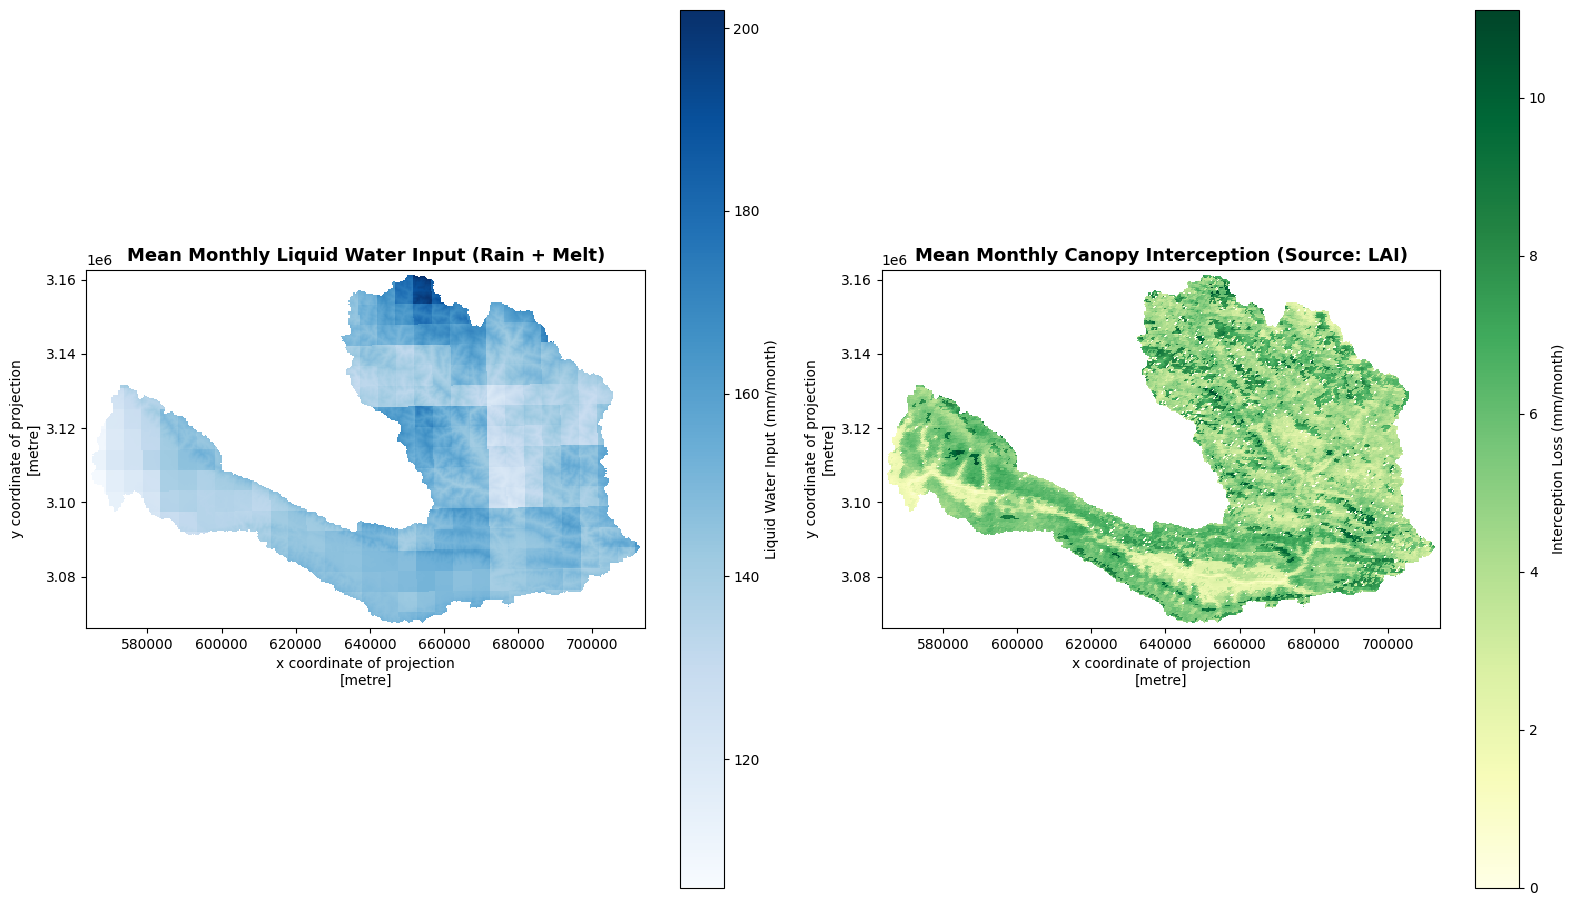

Canopy Interception ready via lai | Mean Interception = 4.9 mm/mo (3.4% of rain + melt) | Mean Net Precip (Pnet) = 139.7 mm/mo


In [6]:
# ==============================================================================
# CANOPY INTERCEPTION & MONTHLY WATER BALANCE COMPUTATION
# Calculates how much rainfall/meltwater is caught by tree leaves and plant leaves
# (interception) before reaching the ground to feed soil moisture and runoff.
# ==============================================================================

if INT_SOURCE == 'wapor':
    # --- Option A: Download actual canopy interception data from FAO WaPOR ---
    import ee, geemap

    # 1. Connect to Google Earth Engine
    try:
        ee.Initialize(project=EE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=EE_PROJECT)

    # 2. Define the geographic box covering our river basin
    region = ee.Geometry.Rectangle(kw.lonlat_bbox(gs))

    # 3. Load monthly canopy interception rasters from FAO's WaPOR database
    wapor_i = (
        ee.ImageCollection('FAO/WAPOR/2/L1_I_M')
        .filterDate(START, END)
        .filterBounds(region)
    )

    # 4. Download and convert the WaPOR images into our project's NetCDF format
    geemap.download_ee_image_collection(
        wapor_i, 'wapor_i', scale=gs['res'], region=region, crs=UTM
    )
    I = kw.tif_stack_to_nc('wapor_i', 'I', P.time.values, gs, nc='I.nc')

else:
    # --- Option B: Estimate interception dynamically using Leaf Area Index (LAI) & Rainy Days ---
    # Calculates how much water plant leaves trap based on leaf density (LAI),
    # daily rainfall depth, and storm frequency (NRD).
    I = kw.interception_from_lai(LAI, Pin, NRD=NRD, k=INT_K)   # keywords: LAI first, then rainfall, rain days
    I.to_netcdf('I.nc')

# 5. Calculate net precipitation reaching the ground (Total Liquid Input minus Interception)
Pnet = (Pin - I).clip(min=0)
Pnet.name = 'Pnet'
Pnet.to_netcdf('Pnet.nc')


# ==============================================================================
# MAP VISUALIZATION: Basin-Wide Water Inputs & Canopy Interception
# ==============================================================================

# Create a large 2-panel map canvas for high-resolution watershed viewing
fig, ax = plt.subplots(1, 2, figsize=(16, 12))

# ------------------------------------------------------------------------------
# Map 1: Annual Mean Liquid Water Input (Rain + Snowmelt + Glacier Ice Melt)
# ------------------------------------------------------------------------------
pin_mean = Pin.where(mask == 1).mean(dim='time')
pin_mean.plot(
    ax=ax[0],
    cmap='Blues',
    cbar_kwargs={'label': 'Liquid Water Input (mm/month)', 'shrink': 0.75},
)
ax[0].set_title(
    'Mean Monthly Liquid Water Input (Rain + Melt)',
    fontsize=13,
    fontweight='bold',
)

# ------------------------------------------------------------------------------
# Map 2: Annual Mean Canopy Interception (Water Caught by Vegetation)
# ------------------------------------------------------------------------------
i_mean = I.where(mask == 1).mean(dim='time')
i_mean.plot(
    ax=ax[1],
    cmap='YlGn',
    cbar_kwargs={'label': 'Interception Loss (mm/month)', 'shrink': 0.75},
)
ax[1].set_title(
    f'Mean Monthly Canopy Interception (Source: {INT_SOURCE.upper()})',
    fontsize=13,
    fontweight='bold',
)

# ------------------------------------------------------------------------------
# AUTOMATIC WATERSHED SPATIAL ZOOM LOGIC
# Crops the map views tightly around the active watershed boundary (mask == 1)
# ------------------------------------------------------------------------------
mask_y, mask_x = np.where(mask.values == 1)
if len(mask_x) > 0:
    margin = 5  # Add a 5-pixel boundary buffer around the watershed
    x_vals = Pnet.x.values
    y_vals = Pnet.y.values

    x_min = x_vals[max(0, mask_x.min() - margin)]
    x_max = x_vals[min(len(x_vals) - 1, mask_x.max() + margin)]
    y_min = y_vals[max(0, mask_y.min() - margin)]
    y_max = y_vals[min(len(y_vals) - 1, mask_y.max() + margin)]

    # Apply tight watershed zoom coordinates to both map axes
    for a in ax:
        a.set_xlim(min(x_min, x_max), max(x_min, x_max))
        a.set_ylim(min(y_min, y_max), max(y_min, y_max))
        a.set_aspect('equal')

plt.tight_layout()
plt.show()

# 6. Print summary statistics comparing basin-wide average totals
print(
    'Canopy Interception ready via',
    INT_SOURCE,
    '| Mean Interception =',
    round(float(I.where(mask == 1).mean()), 1),
    'mm/mo',
    f'({100 * float(I.where(mask == 1).sum() / Pin.where(mask == 1).sum()):.1f}% of rain + melt)',
    '| Mean Net Precip (Pnet) =',
    round(float(Pnet.where(mask == 1).mean()), 1),
    'mm/mo',
)

## 4c · Soil available water content — AWC = field capacity − wilting point  *(optional, recommended)*

**What this does.** The soil 'bucket' size is `SMmax = rooting_depth × AWC`. By default `AWC` is a single
constant (0.12 m³/m³) for the whole basin. This cell instead builds a **spatial** AWC from soil data:
`AWC = θ(field capacity, 33 kPa) − θ(wilting point, 1500 kPa)`, depth-averaged over the root zone (0–100 cm).

- **`AWC_SOURCE='soilgrids'`** *(recommended)* — ISRIC SoilGrids 250 m v2.0 has **both** FC (`wv0033`) and
  PWP (`wv1500`), so AWC is a true FC−PWP field.
- **`AWC_SOURCE='openlandmap'`** — OpenLandMap on GEE publishes FC (33 kPa) but not PWP, so PWP is *assumed*
  as `PWP_FRACTION × FC` (a documented approximation).
- **`AWC_SOURCE='constant'`** — keep the uniform `AWC`.

It writes `awc_spatial.nc`, which the flux cell below picks up automatically (via `kw.smmax_from_lu`).

In [7]:
# Spatial AWC = field capacity (33 kPa) − wilting point (1500 kPa), depth-averaged 0–100 cm.
if AWC_SOURCE in ('soilgrids', 'openlandmap'):
    import ee, geemap
    try: ee.Initialize(project=EE_PROJECT)
    except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
    region = ee.Geometry.Rectangle(kw.lonlat_bbox(gs))
    if AWC_SOURCE == 'soilgrids':
        # ISRIC SoilGrids 250 m v2.0: wv0033/wv1500; bands val_<depth>_mean in cm3/cm3 (= m3/m3).
        # NOTE: depth labels use UNDERSCORES (val_60_100cm_mean), not hyphens.
        fc  = ee.Image('ISRIC/SoilGrids250m/v2_0/wv0033')     # 33 kPa   = field capacity
        pwp = ee.Image('ISRIC/SoilGrids250m/v2_0/wv1500')     # 1500 kPa = wilting point
        layers = [('0_5cm', 5), ('5_15cm', 10), ('15_30cm', 15), ('30_60cm', 30), ('60_100cm', 40)]
        awc = ee.Image(0); tot = 0
        for d, th in layers:
            a = fc.select(f'val_{d}_mean').subtract(pwp.select(f'val_{d}_mean')).max(0)   # cm3/cm3 = m3/m3
            awc = awc.add(a.multiply(th)); tot += th
        awc = awc.divide(tot).rename('awc')                   # root-zone mean AWC (m3/m3)
    else:  # OpenLandMap FC only (33 kPa, volumetric %); PWP assumed = PWP_FRACTION x FC
        fc = ee.Image('OpenLandMap/SOL/SOL_WATERCONTENT-33KPA_USDA-4B1C_M/v01')
        layers = [('b0', 10), ('b10', 20), ('b30', 30), ('b60', 40)]
        theta = ee.Image(0); tot = 0
        for b, th in layers:
            theta = theta.add(fc.select(b).multiply(0.01).multiply(th)); tot += th   # % -> fraction
        awc = theta.divide(tot).multiply(1.0 - PWP_FRACTION).rename('awc')
    geemap.download_ee_image(awc.clip(region), 'awc_spatial.tif', scale=gs['res'], region=region, crs=UTM)
    _a = kw.regrid('awc_spatial.tif', gs).squeeze(drop=True).clip(0.03, 0.30)         # sane m3/m3 bounds
    _a.name = 'awc'; _a.to_netcdf('awc_spatial.nc')
    print('spatial AWC (%s): mean %.3f | range %.3f-%.3f m3/m3 -> awc_spatial.nc'
          % (AWC_SOURCE, float(_a.mean()), float(_a.min()), float(_a.max())))
else:
    if os.path.exists('awc_spatial.nc'): os.remove('awc_spatial.nc')
    print('AWC = constant %.3f m3/m3 (set AWC_SOURCE=soilgrids for a soil-based FC-PWP field)' % AWC)

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python
/usr/local/lib/python3.13/dist-packages/geemap/common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/1 tiles [00:00<?]

spatial AWC (soilgrids): mean 0.174 | range 0.090-0.244 m3/m3 -> awc_spatial.nc


/usr/local/lib/python3.13/dist-packages/geedim/image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


**In plain terms — running the bucket.** Now we step through the months. Each month: add rain (minus interception), take out ET, and whatever the soil cannot hold becomes runoff or percolation. The clever part is bookkeeping where the ET came from — rain-fed soil water is **green**, anything extra that must have come from irrigation or a shallow water table is **blue**. Green + blue always adds back to the satellite ET; that identity is our check.

Blue ET is supplied from **outside** the bucket — rivers, groundwater, irrigation — so with `NET_BLUE=True` it is subtracted from the basin outflow (§5b–5c): water that a field consumes from the river does not also leave at the outlet.

## 5 · Fluxes: the hydroloop model — or (optional) MIKE SHE

Default (`MODEL_SOURCE='hydroloop'`) runs the pixel water balance from Lab-4 inputs. Optionally (`MODEL_SOURCE='mike_she'`) ingest a calibrated MIKE SHE run instead: fill `MIKE_MAP` with the .dfs2 outputs (ET, overland flow, recharge, interception, and — if irrigation is modelled — blue/green ET). They are aggregated to monthly and regridded to the WA+ grid. Use one source per flux; MIKE SHE also gives discharge & groundwater storage that strengthen Sheet 1 and Sheets 5/6. Needs `mikeio`.

In [8]:
# ==============================================================================
# HYDROLOGICAL FLUX SIMULATION & RUNOFF/RECHARGE BALANCING
# Simulates how water moves through the soil: partitioning water into surface
# runoff (rivers), soil storage, plant evaporation, and deep groundwater recharge.
# ==============================================================================

if MODEL_SOURCE == 'mike_she':
    # --- Option A: Ingest results from a external MIKE SHE numerical model ---

    # 1. Install the 'mikeio' library to read MIKE binary format files (.dfs2) in Colab
    if IN_COLAB:
        get_ipython().system('pip -q install mikeio')

    # 2. Read MIKE SHE model output files and re-project them onto our basin's standard 300m grid
    cubes = kw.load_mike_she(MIKE_MAP, gs, MIKE_CRS)

    # 3. Extract key water fluxes if present in the imported MIKE SHE model
    if 'et' in cubes: ET = cubes['et']
    if 'i'  in cubes: I  = cubes['i']

    # 4. Filter for specific water components (rainfed ET, irrigated ET, surface runoff, groundwater recharge)
    r = {k: cubes[k] for k in ['etrain', 'etincr', 'sro', 'perc'] if k in cubes}
    print('MIKE SHE model outputs successfully loaded:', list(cubes))

else:
    # --- Option B: the WA+ soil-moisture balance (hydroloop) ---
    # Soil bucket per pixel: SMmax = root depth (kw.ROOT_DEPTH_M, by WA+ class) × 1000 × AWC
    if os.path.exists('awc_spatial.nc'):
        AWC_FIELD = xr.open_dataarray('awc_spatial.nc').squeeze(drop=True)
        _yd, _xd = lu.dims[-2], lu.dims[-1]
        AWC_FIELD = AWC_FIELD.rename({AWC_FIELD.dims[-2]: _yd, AWC_FIELD.dims[-1]: _xd})
        if AWC_FIELD.shape != lu.shape:
            AWC_FIELD = AWC_FIELD.interp({_yd: lu[_yd], _xd: lu[_xd]}, method='nearest')
        else:
            AWC_FIELD = AWC_FIELD.assign_coords({_yd: lu[_yd].values, _xd: lu[_xd].values})
        print('AWC: spatial field from awc_spatial.nc (basin mean %.3f m³/m³)' % float(AWC_FIELD.where(mask == 1).mean()))
    else:
        AWC_FIELD = AWC
        print(f'AWC: constant {AWC} m³/m³')
    SMmax = kw.smmax_from_lu(lu, awc=AWC_FIELD)
    # Interception that evaporates is part of the satellite ET (green); the soil supplies ET − interception.
    r = kw.run_sm_balance(Pin, ET, I, NRD, SMmax, cf=CF, sm_init_frac=SM_INIT)
    for k in ['etrain', 'etincr', 'sro', 'perc', 'sm']:
        r[k].to_netcdf(f'{k}.nc')
    sro, perc = r['sro'], r['perc']

print('Hydrological flux data ready:', list(r))

AWC: spatial field from awc_spatial.nc (basin mean 0.176 m³/m³)
Hydrological flux data ready: ['etrain', 'etincr', 'sro', 'perc', 'sm']


## 5b · Check the volume against the Kusum gauge  *(why tuning CF cannot fix it)*

Because green + blue ET equals the satellite ET by construction, the model's annual outflow is fixed by the inputs:

$$Q_{model} \;\approx\; P_{in} - ET + ET_{blue} - \Delta SM \qquad\Rightarrow\qquad Q_{model,\,net} \;=\; Q_{model} - ET_{blue} \;\approx\; P_{in} - ET$$

`CF` only moves water between runoff and percolation — it changes **when** water leaves, not **how much**. So instead of tuning `CF`, this cell puts three numbers side by side: the **gauge**, the **satellite water balance** (P − ET), and the **model**. If P − ET is already far from the gauge, the bias sits in the inputs — the rainfall bias correction (Lab 2) or the ET product — and that is where to fix it.

In [9]:
import os, numpy as np, pandas as pd
RES = gs['res']
_oc = os.path.join(KW_DIR if 'KW_DIR' in dir() else '.', 'discharge_outlet.csv')
if not os.path.exists(_oc): _oc = 'discharge_outlet.csv'
ann = lambda s: float(s.groupby(s.index.year).sum(min_count=12).dropna().mean())      # mean of complete years
mcm = lambda da: kw.to_mcm(da, mask, RES)
q_sro, q_perc, q_blue = mcm(sro), mcm(perc), mcm(r['etincr'])
vol = {'P + melt (liquid input)': ann(mcm(Pin)), 'ET (satellite)': ann(mcm(ET)),
       '  of which interception': ann(mcm(I)), '  of which blue ET': ann(q_blue),
       'P − ET  (satellite water balance)': ann(mcm(Pin)) - ann(mcm(ET)),
       'runoff + percolation': ann(q_sro + q_perc),
       'model outflow' + (' (net of blue ET)' if NET_BLUE else ''): ann(q_sro + q_perc - (q_blue if NET_BLUE else 0))}
Q_OBS = None
if os.path.exists(_oc):
    obs = pd.read_csv(_oc, index_col=0, parse_dates=True)['vol_MCM']
    obs = obs[obs.index.year.isin(sorted(set(P['time'].dt.year.values)))]
    Q_OBS = ann(obs); vol['gauged outflow (Kusum)'] = Q_OBS
print(pd.Series(vol).round(0).to_string())
if Q_OBS:
    b_in  = 100 * (vol['P − ET  (satellite water balance)'] / Q_OBS - 1)
    b_mod = 100 * (list(vol.values())[6] / Q_OBS - 1)
    print(f"\nsatellite P − ET is {b_in:+.0f}% vs the gauge; the model outflow is {b_mod:+.0f}%.")
    print('The model cannot beat P − ET on annual volume. A large gap means P too high and/or ET too low:')
    print("  check that Lab 2 bias-corrected P against the real DHM gauges, and compare ET_SOURCE='mod16' vs 'wapor'.")
else:
    print('\n(no discharge_outlet.csv — run 00_Setup with the HydroMetData to add the gauge)')

P + melt (liquid input)              11034.0
ET (satellite)                        4958.0
  of which interception                374.0
  of which blue ET                     636.0
P − ET  (satellite water balance)     6076.0
runoff + percolation                  6772.0
model outflow (net of blue ET)        6135.0
gauged outflow (Kusum)                4888.0

satellite P − ET is +24% vs the gauge; the model outflow is +26%.
The model cannot beat P − ET on annual volume. A large gap means P too high and/or ET too low:
  check that Lab 2 bias-corrected P against the real DHM gauges, and compare ET_SOURCE='mod16' vs 'wapor'.


## 5c · Route the outflow through a groundwater store  *(why the dry season was empty)*

Same-month routing sends percolation out immediately, so the model has almost **no flow in Nov–Apr** while the Kusum gauge keeps flowing. A **linear reservoir** fixes the timing: a share `ALPHA` of runoff plus all percolation enters a store $S$ that drains with recession constant $k$ (months); with `NET_BLUE=True`, blue ET is **abstracted from the store** (it is river / groundwater water):

$$Q_{slow}(t) = S(t)\,\left(1 - e^{-1/k}\right), \qquad S(t+1) = S(t) + \alpha\,SRO(t) + PERC(t) - ET_{blue}(t) - Q_{slow}(t)$$

$$Q(t) = (1-\alpha)\,SRO(t) + Q_{slow}(t)$$

`ALPHA` and `k` are fitted to the gauge's **monthly pattern** (Nash–Sutcliffe efficiency). The store conserves volume, so it cannot remove an annual bias (§5b) — it only puts the water in the right months. The routed series is saved as `Q_routed.csv`, and `ALPHA`/`k` go into `hydroloop_params.json` so Lab 6 runs the same model.

NSE same-month = -0.14  ->  with the store = 0.75   (ALPHA = 0.7, k = 3 months)
  note: 490 MCM of blue ET could not be supplied by the store (dry spells)
dry-season mean Dec–Mar (MCM/month): {'observed': 102.0, 'same month': 6.0, 'with store': 248.0}


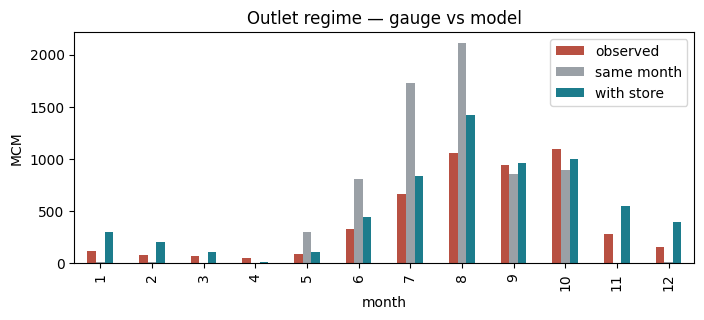

saved Q_routed.csv


In [10]:
ALPHA = K_REC = None
if Q_OBS:
    blue = q_blue if NET_BLUE else None
    def nse(q):
        c = q.index.intersection(obs.dropna().index); o, m = obs.loc[c], q.loc[c]
        return 1 - ((m - o) ** 2).sum() / ((o - o.mean()) ** 2).sum()
    q0 = (q_sro + q_perc - (q_blue if NET_BLUE else 0)).clip(lower=0)
    grid = [(a, k, nse(kw.route_outflow(q_sro, q_perc, None, None, alpha=a, k=k, etincr=blue)))
            for a in np.arange(0.0, 1.001, 0.1) for k in (1, 1.5, 2, 3, 4, 6)]
    ALPHA, K_REC, best = max(grid, key=lambda g: g[2]); ALPHA = round(float(ALPHA), 2)
    Q_routed = kw.route_outflow(q_sro, q_perc, None, None, alpha=ALPHA, k=K_REC, etincr=blue)
    print(f'NSE same-month = {nse(q0):.2f}  ->  with the store = {best:.2f}   (ALPHA = {ALPHA}, k = {K_REC} months)')
    if Q_routed.attrs.get('unmet_blue_MCM', 0) > 1:
        print(f"  note: {Q_routed.attrs['unmet_blue_MCM']:.0f} MCM of blue ET could not be supplied by the store (dry spells)")
    reg = lambda s: s.groupby(s.index.month).mean()
    tab = pd.DataFrame({'observed': reg(obs), 'same month': reg(q0), 'with store': reg(Q_routed)}).round(0)
    print('dry-season mean Dec–Mar (MCM/month):', tab.loc[[12, 1, 2, 3]].mean().round(0).to_dict())
    ax = tab.plot(kind='bar', figsize=(8, 3), color=['#B85042', '#9AA0A6', '#1C7C8C'])
    ax.set_xlabel('month'); ax.set_ylabel('MCM'); ax.set_title('Outlet regime — gauge vs model'); plt.show()
    Q_routed.rename('Q_MCM').to_csv('Q_routed.csv'); kw.save_outputs(['Q_routed.csv'], OUT_DIR)
    print('saved Q_routed.csv')
else:
    print('No gauge — skipping the store calibration (Lab 6 will use same-month routing).')

## 6 · Assemble the cube, check the balance & save

**What this does.** Merges the flux cubes into the analysis-ready cube `bc.nc`, runs the **closure check**, saves everything to Drive and writes **`hydroloop_params.json`** — the exact settings of this run, so Lab 6's scenarios use the same model.

**The closure check.** Per pixel the model satisfies `P_in − green ET − runoff − percolation − Δ soil moisture = 0` (blue ET is supplied from outside the bucket, so it is *not* in this sum). The residual should be ~0; anything else means the inputs or cubes are misaligned.

**In plain terms.** Two quick sanity looks: does green + blue ET add back to the total ET we started with (it must), and does the basin balance close? If either is off, fix the inputs before building sheets — a wrong flux here quietly corrupts every downstream account.

In [11]:
# ==============================================================================
# DATA CUBE ASSEMBLY, SANITY CHECK & OUTPUT EXPORT
# ==============================================================================

# 1. Map standard water flux keys to their respective NetCDF filenames
cube_files = {
    'i': 'I.nc',            # Canopy interception
    'nrd': 'NRD.nc',        # Number of rainy days
    'sro': 'sro.nc',        # Surface runoff
    'etincr': 'etincr.nc',  # Incremental ET
    'etrain': 'etrain.nc',  # Rainfall ET
    'perc': 'perc.nc'       # Deep percolation
}

# 2. Map existing input files using local paths
present_paths = {k: v for k, v in cube_files.items() if os.path.exists(v)}

# 3. Assemble data cube (Pass FULL FILE PATH to assemble_cube)
bc_path = os.path.join(OUT_DIR, 'bc.nc')

# Assemble directly with xarray (one variable per file, renamed to its key)
if os.path.exists(bc_path): os.remove(bc_path)
if True:
    ds_list = []
    for var_key, file_path in present_paths.items():
        ds = xr.open_dataset(file_path)
        # Rename internal variable to match key if necessary
        if len(ds.data_vars) == 1:
            raw_var = list(ds.data_vars)[0]
            ds = ds.rename({raw_var: var_key})
        ds_list.append(ds)

    bc_ds = xr.merge(ds_list)
    bc_ds.to_netcdf(bc_path)

# 4. Check for snow and glacier simulation outputs
snow_names = ['T.nc', 'melt.nc', 'ice_melt.nc', 'swe.nc', 'Pin.nc', 'glacier.nc', 'sm.nc', 'awc_spatial.nc']
snow_files = [f for f in snow_names if os.path.exists(f)]

# 5. Backup ONLY local files to prevent SameFileError on Google Drive
files_to_backup = [
    f for f in (list(present_paths.values()) + ['basin_config.json'] + snow_files)
    if os.path.exists(f) and not f.startswith(OUT_DIR)
]

if files_to_backup:
    kw.save_outputs(files_to_backup, OUT_DIR)

# ------------------------------------------------------------------------------
# EXTRA DIAGNOSTICS: verify the cube before Lab 5
# ------------------------------------------------------------------------------

print("=" * 60)
print("ANALYSIS-READY DATA CUBE SUMMARY")
print("=" * 60)

bc = xr.open_dataset(bc_path) if os.path.exists(bc_path) else None

if bc is not None:
    print(f"Cube Dimensions : {dict(bc.sizes)}")
    print(f"Time Period     : {str(bc.time.values[0])[:10]} to {str(bc.time.values[-1])[:10]} ({bc.sizes['time']} months)")
    print(f"Grid CRS        : {gs['crs']} ({gs['res']} m)")
    print(f"Active Variables: {list(bc.data_vars)}")

    # Basin-wide means
    print("\nBASIN-WIDE MEANS:")
    print("-" * 60)
    for var_key in present_paths.keys():
        if var_key in bc:
            unit = 'days/month' if var_key == 'nrd' else 'mm/month'
            print(f"  • {var_key.upper():<8} ({cube_files[var_key]}): {float(bc[var_key].where(mask == 1).mean()):6.1f} {unit}")
    # Closure of the soil-moisture balance (blue ET comes from outside the bucket)
    if MODEL_SOURCE != 'mike_she' and 'SMmax' in dir():
        res_mm = kw.sm_closure(Pin, r, SMmax, SM_INIT, mask)
        print("-" * 60)
        print(f"Closure  P_in − green ET − SRO − PERC − ΔSM : {res_mm:+.3f} mm/month  ->  "
              + ("PASS" if abs(res_mm) < 0.5 else "CHECK inputs / grid alignment"))
else:
    print("\nWARNING: 'bc.nc' (assembled data cube) was not found. Skipping data cube integrity checks.")

print("=" * 60)
print('Wired flux variables:', list(present_paths.keys()), '| Snow tracking files:', snow_files)
print('Saved outputs to Drive:', OUT_DIR)

# 6. The settings of THIS run, for Lab 6 (scenario_run reproduces this model from them)
params = {'CF': CF, 'SM_INIT': SM_INIT, 'INT_K': INT_K, 'INT_SOURCE': INT_SOURCE, 'NRD_SOURCE': NRD_SOURCE,
          'AWC': AWC, 'awc_file': 'awc_spatial.nc' if os.path.exists('awc_spatial.nc') else None,
          'NET_BLUE': NET_BLUE, 'ALPHA': ALPHA, 'K_REC': K_REC, 'et_includes_interception': True,
          'SNOW_ON': SNOW_ON, 'DDF': DDF, 'T_SNOW': T_SNOW, 'T_MELT': T_MELT, 'LAPSE': LAPSE,
          'T0_SEALEVEL': T0_SEALEVEL, 'GLACIER_ON': GLACIER_ON, 'DDF_ICE': DDF_ICE}
json.dump(params, open('hydroloop_params.json', 'w'), indent=2, default=float)
kw.save_outputs(['hydroloop_params.json'], OUT_DIR)
print('saved hydroloop_params.json:', {k: params[k] for k in ('CF', 'INT_K', 'NET_BLUE', 'ALPHA', 'K_REC', 'awc_file')})

ANALYSIS-READY DATA CUBE SUMMARY
Cube Dimensions : {'time': 48, 'y': 394, 'x': 556}
Time Period     : 2021-01-01 to 2024-12-01 (48 months)
Grid CRS        : EPSG:32644 (300 m)
Active Variables: ['i', 'nrd', 'sro', 'etincr', 'etrain', 'perc']

BASIN-WIDE MEANS:
------------------------------------------------------------
  • I        (I.nc):    4.9 mm/month
  • NRD      (NRD.nc):   12.4 days/month
  • SRO      (sro.nc):   64.4 mm/month
  • ETINCR   (etincr.nc):    8.3 mm/month
  • ETRAIN   (etrain.nc):   56.6 mm/month
  • PERC     (perc.nc):   24.5 mm/month
------------------------------------------------------------
Closure  P_in − green ET − SRO − PERC − ΔSM : +0.000 mm/month  ->  PASS
Wired flux variables: ['i', 'nrd', 'sro', 'etincr', 'etrain', 'perc'] | Snow tracking files: ['T.nc', 'melt.nc', 'ice_melt.nc', 'swe.nc', 'Pin.nc', 'sm.nc', 'awc_spatial.nc']
Saved outputs to Drive: /content/drive/MyDrive/west_rapti/outputs
saved hydroloop_params.json: {'CF': 1.0, 'INT_K': 0.2, 'NET_BLU

## 7 · Interactive — how the knobs move the green/blue split and the outflow  🎛️

Drag **`CF`**, an **AWC multiplier** (× your soil field — 1.0 is the run above) and **`SM_INIT`**; the hydroloop re-runs live and redraws basin green ET, blue ET and runoff, with the blue-ET fraction and the annual outflow against the gauge. Exploration only — nothing is saved.

In [12]:
import ipywidgets as W
from IPython.display import display
_cf  = W.FloatSlider(value=CF, min=0.2, max=3.0, step=0.1, description='CF')
_aws = W.FloatSlider(value=1.0, min=0.5, max=1.5, step=0.05, description='AWC ×')
_smi = W.FloatSlider(value=SM_INIT, min=0.0, max=1.0, step=0.05, description='SM_INIT')
_go  = W.Button(description='Re-run balance', button_style='info', icon='refresh')
_out = W.Output()
def _rerun(_):
    with _out:
        _out.clear_output()
        smmax = kw.smmax_from_lu(lu, awc=AWC_FIELD * _aws.value)
        rr = kw.run_sm_balance(Pin, ET, I, NRD, smmax, cf=_cf.value, sm_init_frac=_smi.value)
        gb = float(rr['etincr'].where(mask == 1).sum() / ET.where(mask == 1).sum())
        q = kw.to_mcm(rr['sro'], mask, RES) + kw.to_mcm(rr['perc'], mask, RES) - (kw.to_mcm(rr['etincr'], mask, RES) if NET_BLUE else 0)
        fig, ax = plt.subplots(figsize=(9, 3))
        for k, lab, col in [('etrain', 'green ET', '#4C9A6B'), ('etincr', 'blue ET', '#2E6E8E'), ('sro', 'runoff', '#E9A63B')]:
            s = kw.basin_series(rr[k], mask); ax.plot(s.index, s.values, label=lab, color=col)
        ax.legend(fontsize=8); ax.set_ylabel('mm/month')
        ax.set_title(f'CF={_cf.value:.1f}  AWC×{_aws.value:.2f}  SM_INIT={_smi.value:.2f}  ->  blue-ET fraction {gb:.2f}'); plt.show()
        print(f'blue ET = {100*gb:.1f}% of ET | annual outflow {ann(q):,.0f} MCM/yr' + (f' vs gauge {Q_OBS:,.0f}' if Q_OBS else ''))
_go.on_click(_rerun)
display(W.HBox([_cf, _aws, _smi]), _go, _out); _rerun(None)

Button(button_style='info', description='Re-run balance', icon='refresh', style=ButtonStyle())

Output()

## 8 · Sensitivity — which assumption decides the split?

A quick sweep (8 model runs): **AWC** scaled around your soil field, and **CF** at three values. Expect AWC to move the blue-ET fraction a lot and the outflow a little; CF barely moves either — it shifts water between runoff and percolation. Record the AWC source and its range in the assumptions log: it is the knob the green/blue split really hangs on.

          blue ET % of ET  outflow MCM/yr
run                                      
AWC ×0.6             22.2            6156
AWC ×0.8             16.9            6157
AWC ×1.0             12.8            6135
AWC ×1.2              9.6            6106
AWC ×1.4              7.0            6076
CF 0.5               13.2            6134
CF 2.0               12.7            6136
CF 3.0               12.6            6137


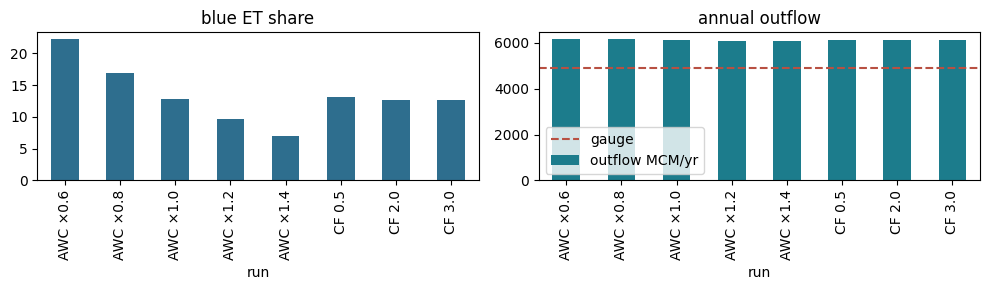

In [13]:
rows = []
for scale in (0.6, 0.8, 1.0, 1.2, 1.4):
    rr = kw.run_sm_balance(Pin, ET, I, NRD, kw.smmax_from_lu(lu, awc=AWC_FIELD * scale), cf=CF, sm_init_frac=SM_INIT)
    rows.append(('AWC ×%.1f' % scale, rr))
for cf_val in (0.5, 2.0, 3.0):
    rr = kw.run_sm_balance(Pin, ET, I, NRD, SMmax, cf=cf_val, sm_init_frac=SM_INIT)
    rows.append(('CF %.1f' % cf_val, rr))
out = []
for name, rr in rows:
    gb = 100 * float(rr['etincr'].where(mask == 1).sum() / ET.where(mask == 1).sum())
    q = ann(kw.to_mcm(rr['sro'], mask, RES) + kw.to_mcm(rr['perc'], mask, RES) - (kw.to_mcm(rr['etincr'], mask, RES) if NET_BLUE else 0))
    out.append({'run': name, 'blue ET % of ET': round(gb, 1), 'outflow MCM/yr': round(q)})
sens = pd.DataFrame(out).set_index('run'); print(sens.to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sens['blue ET % of ET'].plot(kind='bar', ax=ax[0], color='#2E6E8E', title='blue ET share')
sens['outflow MCM/yr'].plot(kind='bar', ax=ax[1], color='#1C7C8C', title='annual outflow')
if Q_OBS: ax[1].axhline(Q_OBS, color='#B85042', ls='--', label='gauge'); ax[1].legend()
plt.tight_layout(); plt.show()

## 9 · Independent checks from satellites  *(optional, ⚠️ Earth Engine)*

The hydroloop is calibrated on **one** number series — outlet flow. Two free satellite records test its *internal* behaviour:

1. **Temperature cube vs MODIS night-time land-surface temperature.** `T0_SEALEVEL` is an assumed table. At night, land-surface temperature sits close to the **minimum** air temperature, so the monthly-mean cube should run a few °C **above** night LST (half the day–night range) in every elevation band. A negative gap, or one that drifts with elevation, means the sea-level table or the lapse rate is off. *(In the West Rapti run the gap fell from about +3 °C in the Terai to about 0 °C above 2.5 km — a lapse rate nearer −5.5 °C/km fits better.)*
2. **Soil-moisture timing vs Sentinel-1.** Wetter soil brightens C-band radar. Over cropland, the month-to-month swing in VV backscatter should rise and fall with modelled soil moisture. This checks **timing**, not amounts — vegetation growth also brightens VV.

*(For snow-fed basins such as the Koshi, add a third check: wet snow drops Sentinel-1 backscatter by ~3 dB, so monthly wet-snow area should coincide with the modelled melt months. In the West Rapti, melt is only ~12 MCM/yr, so it is not worth it here.)*

In [14]:
# --- Check 1: temperature cube vs MODIS night LST, by elevation band ---
import ee, geemap, numpy as np, pandas as pd, xarray as xr
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
region = ee.Geometry.Rectangle(kw.lonlat_bbox(gs)); UTM = gs['crs']
lst = ee.ImageCollection('MODIS/061/MOD11A2').filterDate(START, END).select('LST_Night_1km')
clim = ee.Image.cat([lst.filter(ee.Filter.calendarRange(m, m, 'month')).mean()
                     .multiply(0.02).subtract(273.15).rename(f'm{m:02d}') for m in range(1, 13)])
geemap.download_ee_image(clim.clip(region), 'lst_night_clim.tif', scale=1000, region=region, crs=UTM)

Tref = xr.open_dataarray('T.nc') if os.path.exists('T.nc') else T
Tc = Tref.groupby('time.month').mean('time')                              # (month, y, x) air T, °C
L = kw.regrid('lst_night_clim.tif', gs, resampling='bilinear')             # (band, y, x) night LST, °C
L = L.rename({L.dims[0]: 'month'}).assign_coords(month=range(1, 13))
yd, xd = Tc.dims[-2], Tc.dims[-1]
L = L.rename({L.dims[-2]: yd, L.dims[-1]: xd}).interp({yd: Tc[yd], xd: Tc[xd]}, method='nearest')
E = elev if 'elev' in dir() else kw.regrid('dem_utm.tif', gs).squeeze(drop=True)
E = E.rename({E.dims[-2]: yd, E.dims[-1]: xd}).interp({yd: Tc[yd], xd: Tc[xd]}, method='nearest')
bands = [0, 500, 1000, 1500, 2000, 2500, 4000]
rows = []
for lo, hi in zip(bands[:-1], bands[1:]):
    sel = (mask == 1) & (E >= lo) & (E < hi)
    if int(sel.sum()) < 20: continue
    gap = (Tc - L).where(sel).mean([yd, xd])                               # °C per month
    rows.append({'band_m': f'{lo}-{hi}', 'cells': int(sel.sum()),
                 'mean_gap_C': float(gap.mean()), 'min_gap_C': float(gap.min()), 'max_gap_C': float(gap.max())})
tab = pd.DataFrame(rows).round(1); print(tab.to_string(index=False))
print('Expect a POSITIVE gap of a few °C in every band (monthly mean air T above night LST).')
print('Negative gaps -> T0_SEALEVEL too cold; a gap that grows/shrinks with elevation -> revisit LAPSE.')

/usr/local/lib/python3.13/dist-packages/geemap/common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/1 tiles [00:00<?]

   band_m  cells  mean_gap_C  min_gap_C  max_gap_C
    0-500  21924         3.3        2.4        4.8
 500-1000  14360         1.9        0.3        4.0
1000-1500  13300         1.8       -0.3        5.0
1500-2000  11936         1.4       -1.3        5.4
2000-2500   6183         1.1       -2.4        6.3
2500-4000   2962         0.1       -4.3        5.4
Expect a POSITIVE gap of a few °C in every band (monthly mean air T above night LST).
Negative gaps -> T0_SEALEVEL too cold; a gap that grows/shrinks with elevation -> revisit LAPSE.


Fetching monthly Sentinel-1 VV backscatter from Earth Engine (sequentially to avoid concurrent quota limits)...


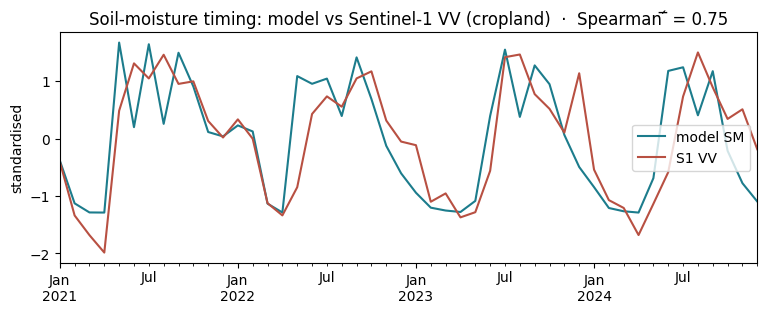

rho > ~0.5: the bucket wets and dries in the right months. Low or negative: check NRD, AWC and the rain timing.
Note: VV also rises with crop growth — use it for TIMING only, never as a soil-moisture amount.


In [15]:
# --- Check 2: modelled soil-moisture timing vs Sentinel-1 VV over cropland ---
import ee, geemap, numpy as np, pandas as pd, os
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)

n_months = int(P.sizes['time'])
geom = geemap.geojson_to_ee('basin.geojson') if os.path.exists('basin.geojson') else ee.Geometry.Rectangle(kw.lonlat_bbox(gs))
crop = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').eq(40)
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(geom).filterDate(START, END)
      .filter(ee.Filter.eq('instrumentMode', 'IW')).filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
      .select('VV'))

# We fetch month-by-month sequentially to avoid 'Too many concurrent aggregations' errors
vv_data = {}
print("Fetching monthly Sentinel-1 VV backscatter from Earth Engine (sequentially to avoid concurrent quota limits)...")
for i in range(n_months):
    try:
        s = ee.Date(START).advance(i, 'month')
        m_str = s.format('YYYY-MM').getInfo()
        img = s1.filterDate(s, s.advance(1, 'month')).mean().updateMask(crop)
        # Using a larger scale (1000m instead of 500m) also speeds up execution and prevents timeouts
        v = img.reduceRegion(ee.Reducer.mean(), geom, 1000, maxPixels=1e10, tileScale=4).get('VV').getInfo()
        vv_data[m_str] = v
        print(f"  {m_str}: {v} dB", end='\r')
    except Exception as e:
        # If a single month fails, we continue so that the notebook run is not disrupted
        s_date = pd.Timestamp(START) + pd.offsets.MonthBegin(i)
        m_str = s_date.strftime('%Y-%m')
        vv_data[m_str] = None

vv = pd.Series(vv_data).astype(float)
vv.index = pd.to_datetime(vv.index)

sm_cube = r['sm'] if 'r' in dir() and 'sm' in r else None
if sm_cube is None:
    print('\nNo soil-moisture cube in r — run §5 with MODEL_SOURCE="hydroloop" first.')
else:
    smc = kw.basin_series(sm_cube.where((lu == 6) | (lu == 8)), mask)       # cropland mean SM (mm)
    df = pd.DataFrame({'model SM': smc, 'S1 VV': vv}).dropna()
    if len(df) > 2:
        z = (df - df.mean()) / df.std()
        rho = z.corr(method='spearman').iloc[0, 1]
        ax = z.plot(figsize=(9, 3), color=['#1C7C8C', '#B85042']); ax.set_ylabel('standardised')
        ax.set_title(f'Soil-moisture timing: model vs Sentinel-1 VV (cropland)  ·  Spearman ́̅ = {rho:.2f}'); plt.show()
        print('rho > ~0.5: the bucket wets and dries in the right months. Low or negative: check NRD, AWC and the rain timing.')
        print('Note: VV also rises with crop growth — use it for TIMING only, never as a soil-moisture amount.')
    else:
        print('\nWarning: Not enough aligned data points to compute correlation or plot. Check Earth Engine connection or time ranges.')

## What feeds Lab 5 and Lab 6
`etrain` (green) and `etincr` (blue) ET, `sro`, `perc` and the land use drive the four WA+ sheets in Lab 5. Lab 6 reads `hydroloop_params.json` (and `awc_spatial.nc`) so its scenarios re-run **this** model, and `Q_routed.csv` gives the outlet regime with the groundwater store.